# Lab01 · Sprint 1

**Данные:** Wine Quality (красное и белое вино)  
**Основная случайная величина:** `alcohol` — содержание алкоголя, % об.

**Ход исследования:** происхождение случайности → EDA и распределения → масштабирование → выборочный анализ → корреляция с `quality` → нормы → собственный kNN → выводы.

В анализе распределений сохраняем все наблюдения, включая совпадающие. Для прогноза качества разделяем данные по группам одинаковых химических профилей, чтобы идентичные признаки не оказывались одновременно в обучении и проверке. Все вычисления воспроизводимы при фиксированном `random_state`.

## 1. Данные и природа случайной величины

Содержание этанола формируется в процессе брожения и зависит от сахаристости сусла, температуры, активности дрожжей, условий выращивания винограда и режима ферментации. Для случайно выбранного образца эти факторы заранее не заданы полностью. Поэтому `alcohol` удобно моделировать как **непрерывную случайную величину**; значения в таблице — её наблюдаемые реализации. Это обоснование статистической модели, а не доказательство принципиальной невозможности детерминированного описания химического процесса.

Данные Cortez et al. содержат физико-химические измерения и отдельную дегустационную оценку `quality`. Сначала проверим размерность, пропуски и совпадающие строки, чтобы понимать, с какой совокупностью работаем.

**Данные:** *Wine Quality*, UCI Machine Learning Repository, DOI: 10.24432/C56S3T. **Научная основа:** Cortez et al. (2009), DOI: 10.1016/j.dss.2009.05.016; Nebot, Mugica, Escobet (2015), DOI: 10.5220/0005551905010507.

**Что делаем в коде?** Подключаем библиотеки, задаём оформление графиков и читаем два CSV. Проверяем размеры таблиц, пропуски и повторяющиеся строки (так проще заметить ошибку загрузки до начала анализа).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from pathlib import Path
from IPython.display import display

# Единая палитра: пыльная роза для красного вина, тёплое золото для белого💅🏻₊ ⊹
PINK, GOLD, DARK = '#A66A80', '#B9A16B', '#52545A'
GRID, LIGHT = '#E9E5E3', '#F8F6F5'
plt.rcParams.update({
    'figure.figsize': (10, 4.8), 'figure.dpi': 115,
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.titlesize': 12, 'axes.titleweight': 'medium',
    'axes.labelcolor': DARK, 'text.color': DARK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#D7D2D0', 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': .7, 'grid.alpha': .85,
    'xtick.color': DARK, 'ytick.color': DARK,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.bbox': 'tight'
})

def finish(fig, title):
    """Одинаковые заголовки и отступы для всех графиков."""
    fig.suptitle(title, fontsize=14, y=1.02, fontweight='medium')
    fig.tight_layout()
    plt.show()

# Загружаем CSV.
if not (Path('winequality-red.csv').exists() and Path('winequality-white.csv').exists()):
    try:
        from google.colab import files
        print('Загрузите winequality-red.csv и winequality-white.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Поместите оба CSV рядом с ноутбуком.')

red = pd.read_csv('winequality-red.csv', sep=';')
white = pd.read_csv('winequality-white.csv', sep=';')
assert red.shape == (1599, 12) and white.shape == (4898, 12)
for name, df in [('Красное', red), ('Белое', white)]:
    print(f'{name}: {len(df)} наблюдений, пропусков {df.isna().sum().sum()}, '
          f'полных дубликатов {df.duplicated().sum()}')

Красное: 1599 наблюдений, пропусков 0, полных дубликатов 240
Белое: 4898 наблюдений, пропусков 0, полных дубликатов 937


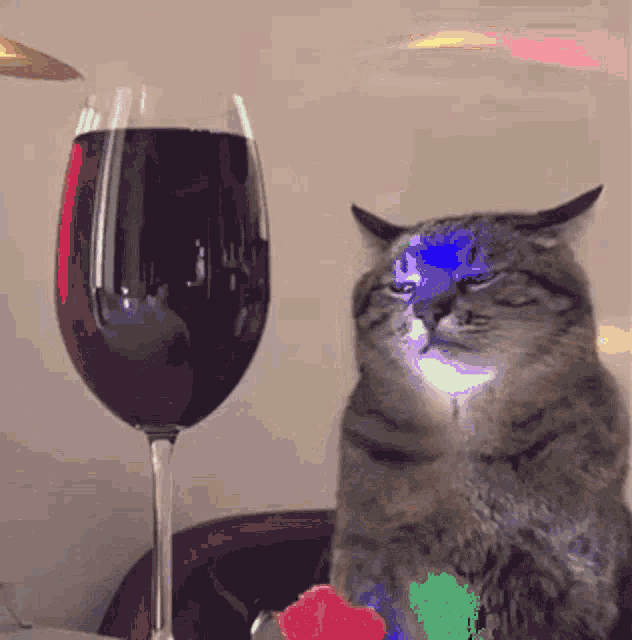

## 2. EDA и описание распределений

Начнём с среднего, медианы, дисперсии, стандартного отклонения, квартилей и асимметрии. Выборочная дисперсия вычисляется с поправкой Бесселя (`ddof=1`):

$$\bar x=\frac{1}{n}\sum_{i=1}^n x_i,\qquad s^2=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2.$$

Гистограммы покажут форму распределения, а Q-Q графики и тест Д’Агостино-Пирсона помогут проверить нормальность. Поскольку наблюдений много, даже небольшие отклонения могут оказаться статистически значимыми.

**Сначала посмотрим на сами данные.** Считаем основные статистики `alcohol` отдельно для красного и белого вина, затем строим гистограммы. Пунктирная линия отмечает среднее: по ней удобно сравнивать положение распределений.

,Красное,Белое
n,1599.0000,4898.0000
Среднее,10.4230,10.5143
Медиана,10.2000,10.4000
Дисперсия,1.1356,1.5144
СКО,1.0657,1.2306
Минимум,8.4000,8.0000
Q1,9.5000,9.5000
Q3,11.1000,11.4000
Максимум,14.9000,14.2000
Асимметрия,0.8608,0.4873


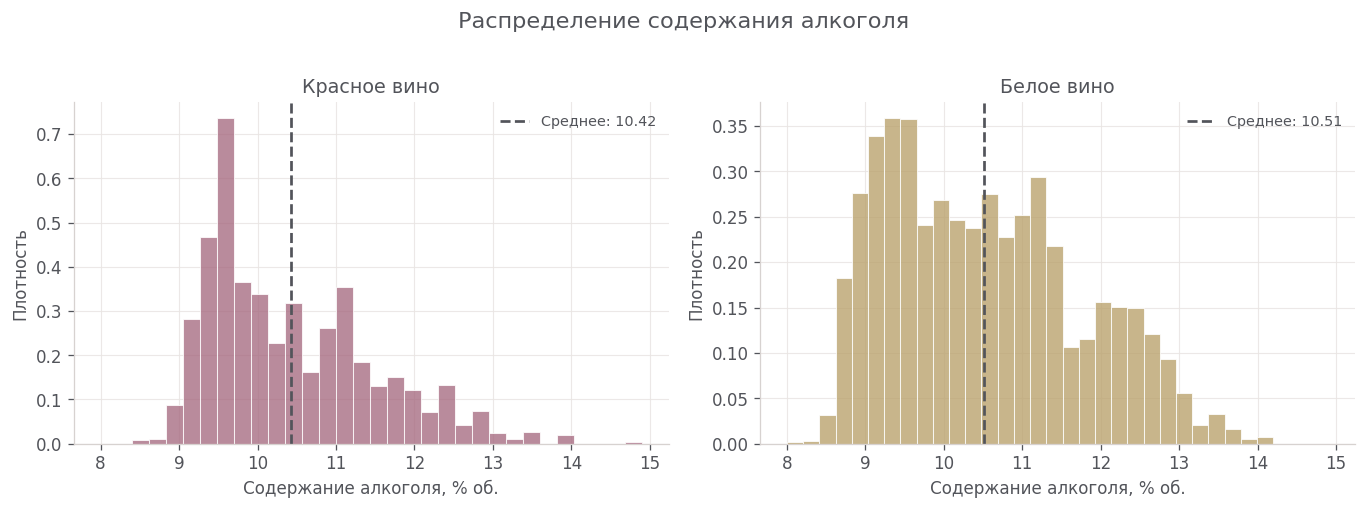

In [3]:
# Собираем статистики в одну таблицу для наглядного сравнения.
def summary(x):
    return pd.Series({
        'n': len(x), 'Среднее': x.mean(), 'Медиана': x.median(),
        'Дисперсия': x.var(ddof=1), 'СКО': x.std(ddof=1),
        'Минимум': x.min(), 'Q1': x.quantile(.25),
        'Q3': x.quantile(.75), 'Максимум': x.max(),
        'Асимметрия': x.skew(), 'Эксцесс': x.kurt()
    })

display(pd.DataFrame({'Красное': summary(red.alcohol),
                      'Белое': summary(white.alcohol)}).round(4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True)
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    ax.hist(df.alcohol, bins=30, density=True, color=color,
            alpha=.78, edgecolor='white', linewidth=.65)
    ax.axvline(df.alcohol.mean(), color=DARK, ls='--', lw=1.7,
               label=f'Среднее: {df.alcohol.mean():.2f}')
    ax.set(title=f'{name} вино', xlabel='Содержание алкоголя, % об.',
           ylabel='Плотность')
    ax.legend(frameon=False, fontsize=9)
    ax.set_axisbelow(True)
finish(fig, 'Распределение содержания алкоголя')

**Насколько распределение похоже на нормальное?** На Q-Q графике точки при нормальности должны располагаться примерно вдоль прямой. Дополнительно проверяем это критерием Д’Агостино-Пирсона при уровне значимости 0,05.

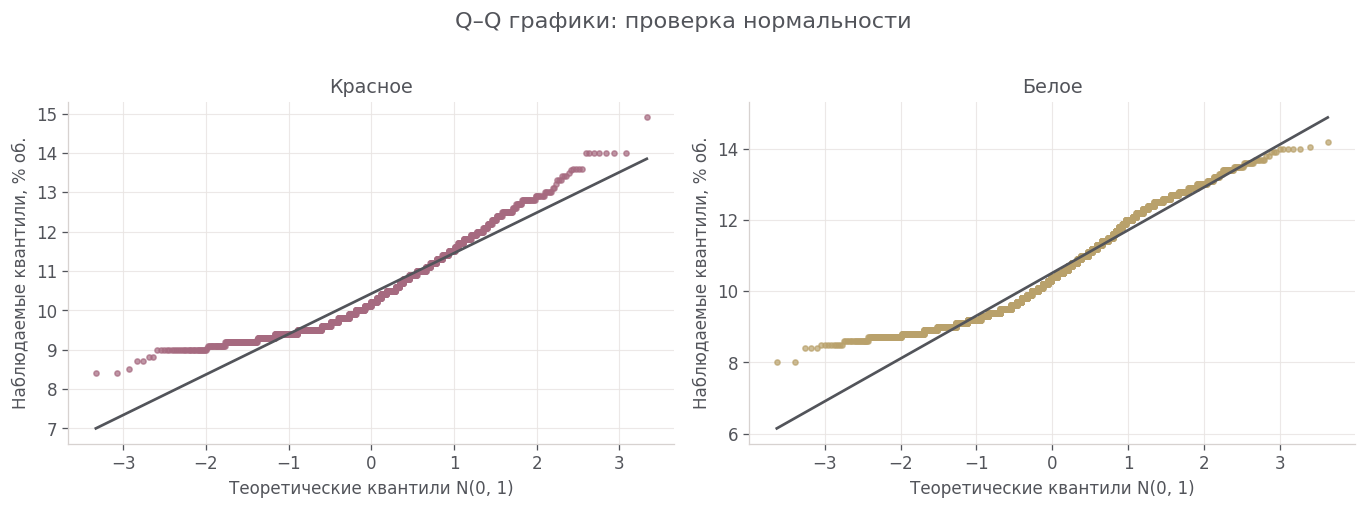

,Тип вина,K²,p-value,"Решение (α = 0,05)"
0,Красное,154.178070,3.316329e-34,H₀ отвергается
1,Белое,430.318952,3.609332e-94,H₀ отвергается


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
rows = []
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    # Q-Q сравнивает квантили данных с квантилями нормальной модели.
    stats.probplot(df.alcohol, dist='norm', plot=ax)
    ax.get_lines()[0].set(color=color, markersize=3.2, alpha=.7)
    ax.get_lines()[1].set(color=DARK, linewidth=1.7)
    ax.set(title=name, xlabel='Теоретические квантили N(0, 1)',
           ylabel='Наблюдаемые квантили, % об.')
    test = stats.normaltest(df.alcohol)
    rows.append((name, test.statistic, test.pvalue,
                 'H₀ отвергается' if test.pvalue < .05 else 'Нет оснований отвергнуть H₀'))
finish(fig, 'Q–Q графики: проверка нормальности')
display(pd.DataFrame(rows, columns=['Тип вина', 'K²', 'p-value', 'Решение (α = 0,05)']))

### Теоретические модели и критерий AIC

Поскольку `alcohol` положителен и имеет правостороннюю асимметрию, сравним три семейства распределений:

- **Нормальное:** $f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp[-(x-\mu)^2/(2\sigma^2)]$.
- **Логнормальное:** $f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp[-(\ln x-\mu)^2/(2\sigma^2)]$, $x>0$.
- **Гамма:** $f(x)=\frac{x^{a-1}e^{-x/\theta}}{\Gamma(a)\theta^a}$, $x>0$.

$\mu,\sigma$ - параметры нормальной модели (для логнормальной - параметры логарифма величины), $a$ - параметр формы гамма-распределения, $\theta$ - масштаб. Для двух положительных семейств фиксируем `loc=0`.

Сравнение проводим по $\mathrm{AIC}=2k-2\ln L$: чем меньше AIC, тем лучше компромисс между правдоподобием и сложностью **среди рассмотренных моделей**. При этом минимальный AIC не означает, что распределение точно описывает все данные.

**Попробуем подобрать распределение.** Для каждого типа вина отдельно оцениваем параметры трёх моделей и сравниваем AIC. Выясняем, какая из предложенных формул лучше согласуется с данными.

In [5]:
models = {'Нормальное': stats.norm,
          'Логнормальное': stats.lognorm,
          'Гамма': stats.gamma}
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    for label, dist in models.items():
        # Параметры подгоняем отдельно для каждого типа вина.
        kw = {'floc': 0} if label != 'Нормальное' else {}
        params = dist.fit(x, **kw)
        aic = 2 * len(params) - 2 * np.sum(dist.logpdf(x, *params))
        rows.append((name, label, aic))
aic_df = pd.DataFrame(rows, columns=['Тип вина', 'Распределение', 'AIC'])
display(aic_df.pivot(index='Распределение', columns='Тип вина', values='AIC').round(2))
print('Лучшая модель среди рассмотренных по AIC:')
display(aic_df.loc[aic_df.groupby('Тип вина')['AIC'].idxmin()].round(2))

Тип вина,Белое,Красное
Распределение,,
Гамма,15766.32,4660.60
Логнормальное,15702.50,4623.90
Нормальное,15935.77,4744.16


Лучшая модель среди рассмотренных по AIC:


,Тип вина,Распределение,AIC
4,Белое,Логнормальное,15702.5
1,Красное,Логнормальное,4623.9


## 3. Масштабирование признака

Проверим два способа приведения `alcohol` к единому масштабу:

$$x_{\mathrm{MinMax}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}},\qquad z=\frac{x-\bar x}{s}.$$

Первое преобразование переводит наблюдения в интервал $[0,1]$, второе даёт среднее около нуля и СКО около единицы. Здесь считаем параметры отдельно для красного и белого вина **только для описательного сравнения** (в kNN масштабирование будет настроено только по обучающим данным).

**Проверим масштабирование на практике.** После Min–Max все значения должны оказаться между 0 и 1, а после Z-score среднее станет близким к нулю. Выводим статистики для численной проверки.

In [6]:
# Смотрим, как изменились среднее, разброс и границы после преобразования.
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    variants = {
        'Исходные': x,
        'Min–Max': (x - x.min()) / (x.max() - x.min()),
        'Z-score': (x - x.mean()) / x.std(ddof=1)
    }
    for method, values in variants.items():
        rows.append((name, method, values.mean(), values.std(ddof=1),
                     values.min(), values.max()))
display(pd.DataFrame(rows, columns=[
    'Тип вина', 'Метод', 'Среднее', 'СКО', 'Минимум', 'Максимум'
]).round(4))

,Тип вина,Метод,Среднее,СКО,Минимум,Максимум
0,Красное,Исходные,10.4230,1.0657,8.4000,14.9000
1,Красное,Min–Max,0.3112,0.1639,0.0000,1.0000
2,Красное,Z-score,0.0000,1.0000,-1.8983,4.2011
3,Белое,Исходные,10.5143,1.2306,8.0000,14.2000
4,Белое,Min–Max,0.4055,0.1985,0.0000,1.0000
5,Белое,Z-score,-0.0000,1.0000,-2.0431,2.9950


## 4. Выборки и состоятельность среднего

В рамках нашего эксперимента все строки каждого датасета считаем **условной генеральной совокупностью**. Сравниваем два способа отбора по индексам: с возвращением (индекс может повториться) и без возвращения (каждый индекс выбирается не более одного раза). Одинаковые по значениям строки при этом допустимы.

Для независимого отбора с возвращением $\mathrm{Var}(\bar X_n)=\sigma^2/n$. При простом случайном отборе без возвращения из конечной совокупности из $N$ элементов:

$$\mathrm{Var}(\bar X_n)=\frac{\sigma^2}{n}\frac{N-n}{N-1},$$

где $\sigma^2$ — дисперсия конечной совокупности с делителем $N$. При увеличении $n$ ожидаем уменьшение ошибки оценки среднего. Проверим это повторным моделированием выборок и расчётом RMSE.

**Делаем первые случайные выборки.** Берём по 100 значений двумя способами и сравниваем выборочные средние с полным датасетом.

In [7]:
# Фиксируем генератор (при повторном запуске получим те же выборки).
rng = np.random.default_rng(42)
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    for replace, label in [(False, 'Без возвращения'), (True, 'С возвращением')]:
        sample = rng.choice(x, size=100, replace=replace)
        rows.append((name, label, len(x), len(sample), x.mean(),
                     sample.mean(), sample.var(ddof=1), np.median(sample)))
display(pd.DataFrame(rows, columns=[
    'Тип вина', 'Метод', 'N', 'n', 'Среднее генеральной',
    'Среднее выборки', 'Дисперсия выборки', 'Медиана'
]).round(4))

,Тип вина,Метод,N,n,Среднее генеральной,Среднее выборки,Дисперсия выборки,Медиана
0,Красное,Без возвращения,1599,100,10.4230,10.5465,1.2036,10.40
1,Красное,С возвращением,1599,100,10.4230,10.6190,1.1335,10.45
2,Белое,Без возвращения,4898,100,10.5143,10.5164,1.5585,10.40
3,Белое,С возвращением,4898,100,10.5143,10.5209,1.3653,10.40


**Повторяем эксперимент.** Для каждого размера выборки многократно оцениваем среднее и считаем RMSE относительно среднего полного датасета. На графике будет видно, как уменьшается ошибка.

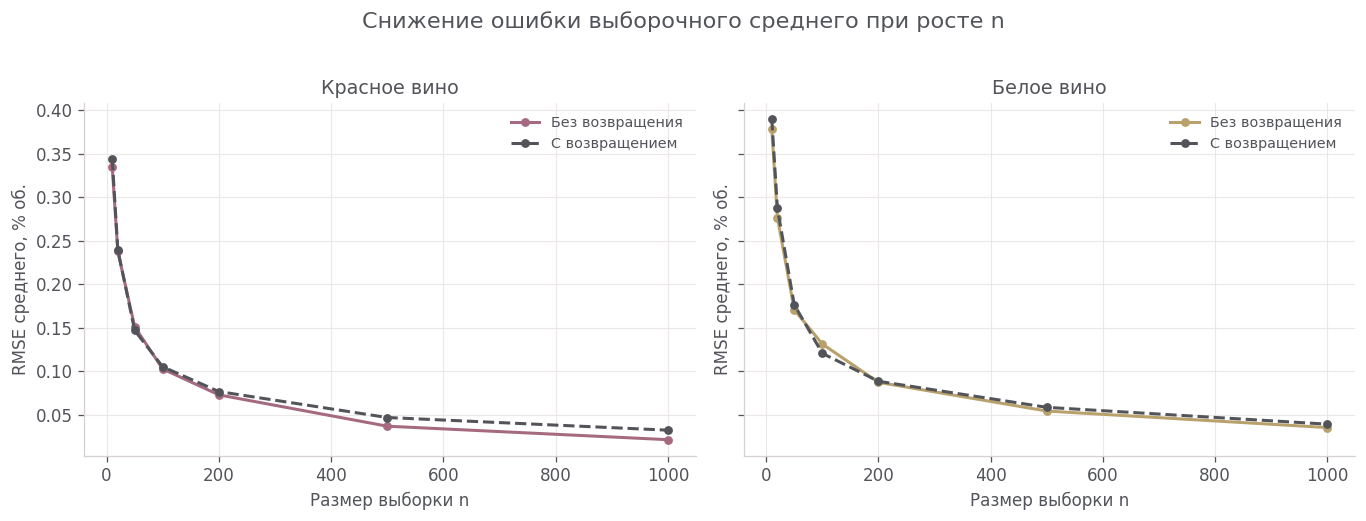

,Тип,Метод,n,RMSE
0,Красное,Без возвращения,10,0.3355
3,Красное,Без возвращения,100,0.1024
6,Красное,Без возвращения,1000,0.0211
7,Красное,С возвращением,10,0.3442
10,Красное,С возвращением,100,0.1049
13,Красное,С возвращением,1000,0.0320
14,Белое,Без возвращения,10,0.3783
17,Белое,Без возвращения,100,0.1312
20,Белое,Без возвращения,1000,0.0350
21,Белое,С возвращением,10,0.3899


In [8]:
sizes = np.array([10, 20, 50, 100, 200, 500, 1000])
B = 400  # число повторных выборок для каждого размера
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
rows = []
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    x = df.alcohol.to_numpy()
    mu = x.mean()  # известное среднее нашей условной генеральной совокупности
    for replace, label, style in [
        (False, 'Без возвращения', '-'), (True, 'С возвращением', '--')
    ]:
        rmse = []
        for size in sizes:
            estimates = np.array([
                rng.choice(x, size=size, replace=replace).mean()
                for _ in range(B)
            ])
            error = np.sqrt(np.mean((estimates - mu) ** 2))
            rmse.append(error)
            rows.append((name, label, size, error))
        ax.plot(sizes, rmse, style, marker='o', markersize=4.5,
                linewidth=1.9, color=color if not replace else DARK,
                label=label)
    ax.set(title=f'{name} вино', xlabel='Размер выборки n',
           ylabel='RMSE среднего, % об.')
    ax.legend(frameon=False, fontsize=9)
    ax.set_axisbelow(True)
finish(fig, 'Снижение ошибки выборочного среднего при росте n')
consistency = pd.DataFrame(rows, columns=['Тип', 'Метод', 'n', 'RMSE'])
display(consistency[consistency.n.isin([10, 100, 1000])].round(4))

## 5. Связь содержания алкоголя с качеством

Проверяем двусторонние гипотезы об отсутствии корреляции:

$$H_0:\rho=0,\qquad H_1:\rho\ne0.$$

Коэффициент **Пирсона** оценивает линейную связь, **Спирмена** — монотонную ранговую. Для каждого используем соответствующий статистический тест и уровень значимости $\alpha=0{,}05$. Малое p-value говорит против отсутствия соответствующей корреляции, но не доказывает причинное влияние алкоголя на качество.

**Теперь проверим связь с качеством.** Рассчитываем корреляции Пирсона и Спирмена, их p-value и строим графики `alcohol`–`quality`. Корреляция показывает статистическую связь, но сама по себе не доказывает причинность.

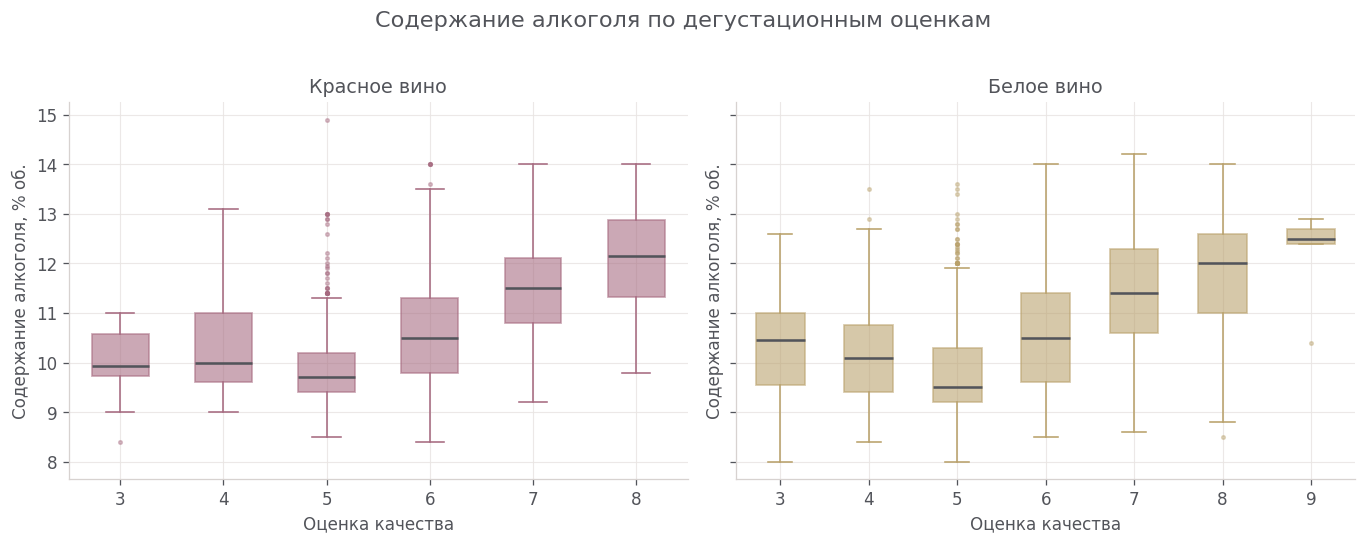

,Тип вина,Пирсон r,p Пирсон,Спирмен ρ,p Спирмен
0,Красное,0.476166,2.831477e-91,0.478532,2.726838e-92
1,Белое,0.435575,5.614770e-226,0.440369,1.659196e-231


In [9]:
# Считаем две корреляции: линейную (Пирсон) и ранговую (Спирмен).
rows = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    pearson = stats.pearsonr(df.alcohol, df.quality)
    spearman = stats.spearmanr(df.alcohol, df.quality)
    rows.append((name, pearson.statistic, pearson.pvalue,
                 spearman.statistic, spearman.pvalue))
    scores = sorted(df.quality.unique())
    groups = [df.loc[df.quality == q, 'alcohol'].values for q in scores]
    bp = ax.boxplot(groups, positions=scores, patch_artist=True, widths=.55,
                    medianprops={'color': DARK, 'linewidth': 1.6},
                    boxprops={'color': color, 'linewidth': 1.1},
                    whiskerprops={'color': color}, capprops={'color': color},
                    flierprops={'marker': 'o', 'markersize': 2.2,
                                'markerfacecolor': color, 'markeredgecolor': color,
                                'alpha': .4})
    for patch in bp['boxes']:
        patch.set(facecolor=color, alpha=.58)
    ax.set(title=f'{name} вино', xlabel='Оценка качества',
           ylabel='Содержание алкоголя, % об.', xticks=scores)
    ax.set_axisbelow(True)
finish(fig, 'Содержание алкоголя по дегустационным оценкам')
corr_df = pd.DataFrame(rows, columns=[
    'Тип вина', 'Пирсон r', 'p Пирсон', 'Спирмен ρ', 'p Спирмен'
])
display(corr_df)

## 6. Нормы и геометрия пространства признаков

Для двух векторов $x,y\in\mathbb R^d$ расстояния задаются нормами разности:

$$d_1(x,y)=\sum_i|x_i-y_i|,\qquad d_2(x,y)=\sqrt{\sum_i(x_i-y_i)^2},\qquad d_\infty(x,y)=\max_i|x_i-y_i|.$$

В двумерном случае единичные линии уровня имеют форму **ромба, окружности и квадрата**.

**Переходим от статистики к геометрии.** Записываем три функции расстояния и строим линии уровня: ромб для L1, окружность для L2 и квадрат для L∞. Так становится понятнее, почему выбор метрики влияет на соседей.

Проверка на векторах (1, 2) и (4, 6): {'L1': 7.0, 'L2': 5.0, 'Linf': 4.0}


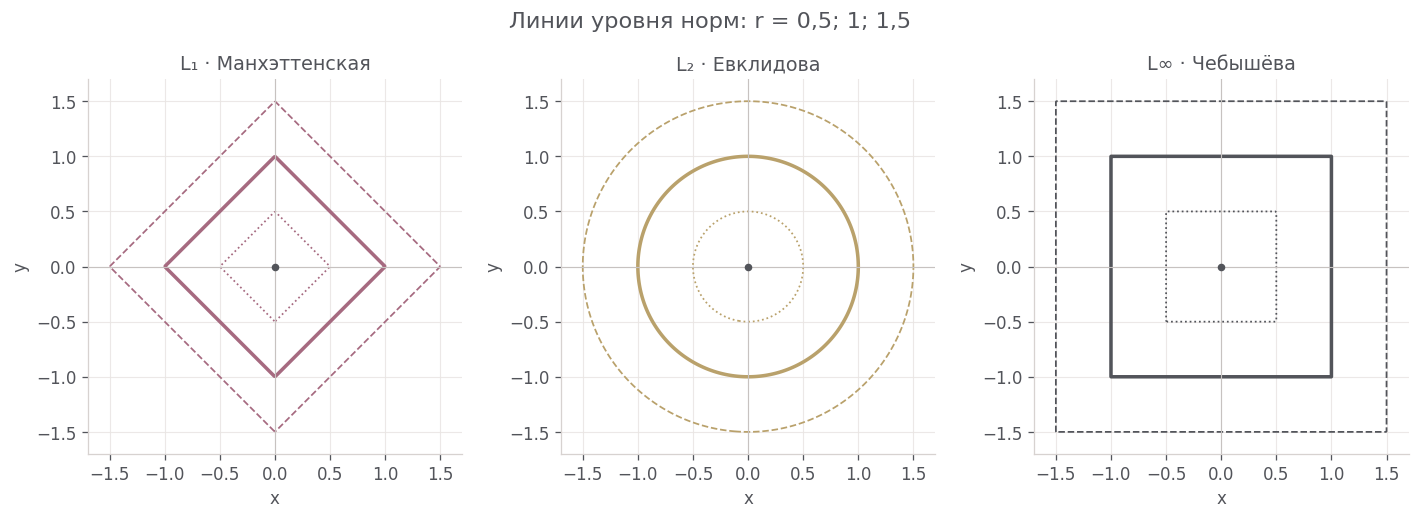

In [10]:
def distance(a, b, metric='L2'):
    """Расстояние между двумя векторами без готовых функций метрик."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if a.shape != b.shape or a.size == 0:
        raise ValueError('Нужны непустые векторы одинаковой формы')
    delta = np.abs(a - b)
    if metric == 'L1':
        return float(delta.sum())
    if metric == 'L2':
        return float(np.sqrt((delta ** 2).sum()))
    if metric == 'Linf':
        return float(delta.max())
    raise ValueError('Неизвестная метрика')

print('Проверка на векторах (1, 2) и (4, 6):',
      {m: distance([1, 2], [4, 6], m) for m in ['L1', 'L2', 'Linf']})

# Строим линии уровней 0.5, 1 и 1.5, чтобы сравнить геометрию норм.
coords = np.linspace(-1.7, 1.7, 350)
XX, YY = np.meshgrid(coords, coords)
levels = [0.5, 1, 1.5]
fields = [np.abs(XX) + np.abs(YY),
          np.sqrt(XX ** 2 + YY ** 2),
          np.maximum(np.abs(XX), np.abs(YY))]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 4.2))
for ax, field, title, color in zip(
    axs, fields, ['L₁ · Манхэттенская', 'L₂ · Евклидова', 'L∞ · Чебышёва'],
    [PINK, GOLD, DARK]
):
    ax.contour(XX, YY, field, levels=levels, colors=[color],
               linewidths=[1.1, 2.2, 1.1], linestyles=['dotted', 'solid', 'dashed'])
    ax.scatter([0], [0], color=DARK, s=14, zorder=4)
    ax.axhline(0, color='#C7C2C0', linewidth=.7)
    ax.axvline(0, color='#C7C2C0', linewidth=.7)
    ax.set(title=title, xlabel='x', ylabel='y', xlim=(-1.7, 1.7),
           ylim=(-1.7, 1.7), aspect='equal')
    ax.set_axisbelow(True)
finish(fig, 'Линии уровня норм: r = 0,5; 1; 1,5')

## 7. kNN: реализация и проверка на данных вина

Прогнозируем `quality` по **11 физико-химическим признакам и типу вина** (12 признаков). Целевая оценка не включается в признаки. Сначала выделяем тестовую выборку, затем из оставшихся данных — валидационную. Одинаковые векторы признаков (с учётом типа вина) относятся только к одной части.

Для вычисления расстояний важно привести признаки к сопоставимому масштабу. Среднее и СКО для стандартизации определяем **только по обучающей части**, иначе в обучение попадёт информация из валидации или теста.

**Готовим данные для проверки kNN.** Разделяем наблюдения на обучение, валидацию и тест. Одинаковые химические профили не должны оказаться в разных частях; параметры стандартизации вычисляем только на обучении.

In [11]:
# Подготавливаем данные для модели.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

# sklearn используем для разбиения и оценочных метрик, но не для самого kNN.
full = pd.concat([red.assign(wine_type=0),
                  white.assign(wine_type=1)], ignore_index=True)
features = [c for c in full.columns if c != 'quality']
X = full[features].to_numpy(dtype=float)
y = full.quality.to_numpy(dtype=int)

# Одинаковые химические профили должны попасть в одну группу.
groups = pd.util.hash_pandas_object(full[features], index=False).to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42)
trainval_idx, test_idx = next(gss.split(X, y, groups))
gss_val = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=43)
a_idx, b_idx = next(gss_val.split(
    X[trainval_idx], y[trainval_idx], groups[trainval_idx]
))
train_idx, val_idx = trainval_idx[a_idx], trainval_idx[b_idx]
assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))

scaler = StandardScaler().fit(X[train_idx])
Xtr, Xv, Xt = (scaler.transform(X[idx]) for idx in
               [train_idx, val_idx, test_idx])
ytr, yv, yt = y[train_idx], y[val_idx], y[test_idx]
print('Train / Validation / Test:', len(ytr), len(yv), len(yt))
print('Пересечения одинаковых профилей: отсутствуют')

Train / Validation / Test: 4182 1022 1293
Пересечения одинаковых профилей: отсутствуют


### Устройство классификатора

Для каждого образца вычисляем расстояние до всех объектов обучения, сортируем индексы по расстоянию и берём первые $k$. Прогноз - наиболее частая оценка среди этих соседей:

$$\hat y(x)=\arg\max_c\sum_{i\in N_k(x)}\mathbf1(y_i=c).$$

Если несколько оценок получили одинаковое число голосов, выбираем ту, у которой **меньше суммарное расстояние** до соседей соответствующего класса; при полном равенстве - меньшую оценку. Сортировка с фиксированным правилом устраняет неоднозначность при равных расстояниях.

**Пишем kNN.** Для каждого нового образца находим расстояния до обучающих, выбираем ближайшие `k` объектов и голосуем за оценку качества. `assert` в конце проверяют базовую логику.

In [12]:
def knn_predict(X_train, y_train, X_query, k=15, metric='L1', batch_size=80):
    """Собственный kNN: расстояния, ближайшие соседи, голосование."""
    if not 1 <= k <= len(X_train):
        raise ValueError('k должно быть от 1 до числа обучающих объектов')
    result = []
    for start in range(0, len(X_query), batch_size):
        # Пакеты позволяют не хранить огромную матрицу расстояний сразу.
        Q = X_query[start:start + batch_size]
        delta = np.abs(Q[:, None, :] - X_train[None, :, :])
        if metric == 'L1':
            dist = delta.sum(axis=2)
        elif metric == 'L2':
            dist = np.sqrt((delta ** 2).sum(axis=2))
        elif metric == 'Linf':
            dist = delta.max(axis=2)
        else:
            raise ValueError('Неизвестная метрика')
        for distances in dist:
            ix = np.argsort(distances, kind='stable')[:k]
            labels = y_train[ix]
            classes, counts = np.unique(labels, return_counts=True)
            tied = classes[counts == counts.max()]
            if len(tied) == 1:
                result.append(tied[0])
            else:
                result.append(min(
                    tied, key=lambda c: (distances[ix[labels == c]].sum(), c)
                ))
    return np.asarray(result, dtype=int)

# Проверка на маленьком примере, где ответ можно получить вручную.
assert distance([0, 0], [3, 4], 'L2') == 5
assert knn_predict(np.array([[0.], [1.], [10.]]),
                   np.array([1, 1, 2]), np.array([[.2]]), k=1)[0] == 1
print('Проверки реализации пройдены')

Проверки реализации пройдены


### Выбор метрики и числа соседей

Сравниваем $L_1$, $L_2$, $L_\infty$ при $k\in\{1,5,11,15,21\}$ на **валидационной** выборке. Основной критерий - Accuracy; при равенстве выбираем меньшую MAE. После выбора гиперпараметров один раз оцениваем модель на независимом тесте (так тест не участвует в настройке).

$$\mathrm{Accuracy}=\frac{1}{n}\sum_i\mathbf1(\hat y_i=y_i),\qquad
\mathrm{MAE}=\frac{1}{n}\sum_i|\hat y_i-y_i|.$$

**Подбираем настройки без подсматривания в тест.** Сравниваем три метрики и несколько значений `k` на валидационной части. На графике отмечаем лучшую комбинацию, которую затем будем проверять отдельно.

,Метрика,k,Accuracy,MAE
0,L1,1,0.4795,0.6370
1,L1,5,0.4980,0.5763
2,L1,11,0.5294,0.5382
3,L1,15,0.5294,0.5391
4,L1,21,0.5333,0.5245
5,L2,1,0.4560,0.6575
6,L2,5,0.5049,0.5705
7,L2,11,0.5323,0.5294
8,L2,15,0.5440,0.5147
9,L2,21,0.5470,0.5127


Лучший вариант: L2, k=21, Accuracy=0.5470, MAE=0.5127


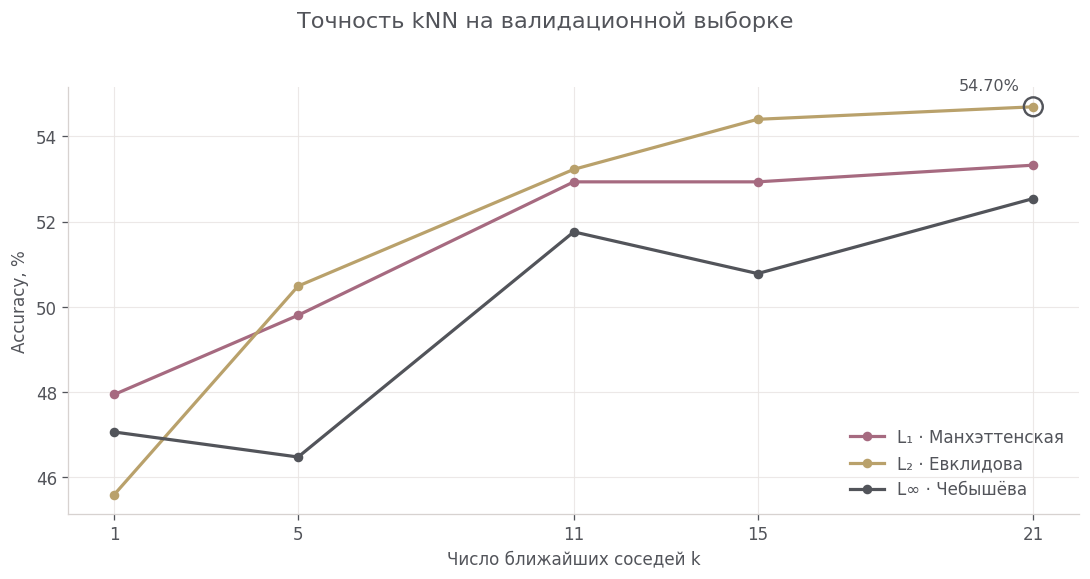

In [13]:
# Сравниваем настройки только на валидации - тест пока не трогаем.
rows = []
for metric in ['L1', 'L2', 'Linf']:
    for k in [1, 5, 11, 15, 21]:
        pred = knn_predict(Xtr, ytr, Xv, k=k, metric=metric)
        rows.append((metric, k, accuracy_score(yv, pred),
                     mean_absolute_error(yv, pred)))
results = pd.DataFrame(rows, columns=['Метрика', 'k', 'Accuracy', 'MAE'])
display(results.round(4))
best = results.sort_values(['Accuracy', 'MAE'],
                           ascending=[False, True]).iloc[0]
print(f'Лучший вариант: {best["Метрика"]}, k={int(best.k)}, '
      f'Accuracy={best.Accuracy:.4f}, MAE={best.MAE:.4f}')

fig, ax = plt.subplots(figsize=(9.6, 4.9))
for metric, color, label in [
    ('L1', PINK, 'L₁ · Манхэттенская'),
    ('L2', GOLD, 'L₂ · Евклидова'),
    ('Linf', DARK, 'L∞ · Чебышёва')
]:
    part = results[results['Метрика'] == metric]
    ax.plot(part.k, part.Accuracy * 100, marker='o', markersize=5,
            linewidth=2, color=color, label=label)
ax.scatter(best.k, best.Accuracy * 100, s=140, facecolors='none',
           edgecolors=DARK, linewidths=1.5, zorder=5)
ax.annotate(f'{best.Accuracy * 100:.2f}%',
            (best.k, best.Accuracy * 100), xytext=(-47, 10),
            textcoords='offset points', fontsize=10)
ax.set(xlabel='Число ближайших соседей k', ylabel='Accuracy, %',
       xticks=[1, 5, 11, 15, 21])
ax.legend(frameon=False, loc='lower right')
ax.set_axisbelow(True)
finish(fig, 'Точность kNN на валидационной выборке')

**Последняя проверка - на отложенном тесте.** Сравниваем наш kNN с простым ориентиром: моделью, которая всегда выбирает наиболее частую оценку. Помимо точных попаданий считаем MAE, RMSE и долю ошибок не более одного балла.

In [15]:
# Финальная оценка: гиперпараметры уже зафиксированы на валидации.
pred_test = knn_predict(Xtr, ytr, Xt, int(best.k), str(best['Метрика']))
majority = pd.Series(ytr).mode().iloc[0]
baseline = np.full_like(yt, majority)
comparison = pd.DataFrame([
    ('kNN', accuracy_score(yt, pred_test),
     mean_absolute_error(yt, pred_test),
     np.sqrt(mean_squared_error(yt, pred_test))),
    ('Частый класс', accuracy_score(yt, baseline),
     mean_absolute_error(yt, baseline),
     np.sqrt(mean_squared_error(yt, baseline)))
], columns=['Модель', 'Accuracy', 'MAE', 'RMSE'])
display(comparison.round(4))
within_one = np.mean(np.abs(yt - pred_test) <= 1)
print(f'Доля прогнозов с ошибкой не более 1 балла: {within_one:.2%}')

,Модель,Accuracy,MAE,RMSE
0,kNN,0.5414,0.5035,0.7722
1,Частый класс,0.4501,0.6141,0.8688


Доля прогнозов с ошибкой не более 1 балла: 95.67%


## Итоговые выводы

**1. Анализ содержания алкоголя**

Мы исследовали 1599 образцов красного и 4898 образцов белого вина. Среднее содержание алкоголя составило **10,42 %** и **10,51 %** соответственно. У белого вина разброс значений оказался немного больше.

Проверка нормальности показала, что распределение `alcohol` отличается от нормального (p-value < 0,05). Из трёх рассмотренных распределений лучше всего подошло **логнормальное** по критерию AIC.

**2. Нормализация и случайные выборки**

Мы выполнили Min–Max нормализацию и Z-score стандартизацию, а также исследовали выборки с возвращением и без него. При увеличении размера выборки ошибка оценки среднего уменьшалась, что согласуется с теорией состоятельности.

**3. Связь алкоголя с качеством вина**

Корреляционный анализ показал **умеренную положительную связь** между содержанием алкоголя и качеством вина. Коэффициент Пирсона составил **0,4762** для красного и **0,4356** для белого вина. В обоих случаях связь статистически значима (p-value < 0,05).

Таким образом, вина с более высоким содержанием алкоголя в среднем получают более высокие оценки, хотя это не доказывает причинно-следственную связь.

**4. Реализация kNN**

Также были реализованы нормы L1, L2, L∞ и алгоритм k ближайших соседей. Лучшей оказалась метрика **L2 при k = 21**.

На тестовой выборке модель показала:

- **Accuracy = 54,14 %**
- **MAE = 0,5035**
- **RMSE = 0,7722**

Точность оказалась на **9,13 процентного пункта выше**, чем у базовой модели. При этом в **95,67 % случаев** ошибка не превышала одного балла.

**Подводя итоги**, мы убедились, что содержание алкоголя обладает статистической вариативностью и связано с оценкой качества вина. Физико-химические характеристики позволяют частично прогнозировать качество, но не определяют его полностью. Несмотря на сравнительно невысокую точность, наш kNN показал результат лучше базового классификатора.

**Источники**
1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Wine Quality. UCI Machine Learning Repository, 2009. DOI: 10.24432/C56S3T.
2. Cortez P. et al. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 47(4), 547–553 (2009). DOI: 10.1016/j.dss.2009.05.016.
3. Nebot À., Mugica F., Escobet A. Modeling Wine Preferences from Physicochemical Properties using Fuzzy Techniques. SIMULTECH 2015, 501–507. DOI: 10.5220/0005551905010507.

<div align="right">
Продолжение следует...
</div>